# DDuo releases as noisy values

[DDuo](https://github.com/uvm-plaid/dduo-python) (package `duet`) tracks
differential-privacy *sensitivity* dynamically: data read through
`duet.pandas.read_csv` comes back wrapped, and the wrapper follows the data
through ordinary pandas and NumPy code, working out how far one person's
record can move every intermediate result. Its mechanisms (`duet.laplace`,
`duet.gauss`, `duet.renyi_gauss`) add noise calibrated to that sensitivity and
return plain numbers.

`noisyvalue.dduo` has drop-in replacements for those mechanisms. Each one
calls DDuo's own mechanism, so calibration, the noise draw and privacy
accounting are DDuo's, and returns a `NoisyFloat` instead: the released number
paired with a posterior over the true value it was computed from. That
posterior then travels through whatever you compute next.

**Setup.** `duet` is not on PyPI, and this integration needs DDuo mechanisms
that support `details=True`. Put a DDuo checkout on `PYTHONPATH` before
starting Jupyter, e.g.
`PYTHONPATH=~/code/github/sbaldasty/dduo-python uv run jupyter lab`.

In [1]:
import os
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import duet
import duet.pandas as dpd
from duet.duet_vals import release_sensitivity

from noisyvalue import dduo, plot_posterior, sample_noisy_values
from noisyvalue.release import SharedLatentRegistry

## The data

Five hundred made-up survey respondents: an age and the hours they worked
last week. DDuo treats a CSV file as a *data source*, so the frame is written
to a temporary file and read back through `duet.pandas`.

In [2]:
rng = np.random.default_rng(1)
people = pd.DataFrame({
    "age": rng.integers(18, 95, 500),
    "hours": rng.normal(38, 12, 500).round().clip(0, 99),
})
path = os.path.join(tempfile.mkdtemp(), "people.csv")
people.to_csv(path, index=False)

df = dpd.read_csv(path)
type(df).__name__

'DuetWrapper'

## What DDuo knows before anything is released

Every tracked value carries two public facts that `noisyvalue.dduo` uses:

- its **release sensitivity**, how far one person can move it, which sets the
  noise scale;
- its **bounds**, a range the true value lies in on *every* possible
  dataset. These come only from public facts (clip limits, "counts are
  non-negative"), never from the data itself.

Neither fact depends on the data. The number of respondents could change and
both would stay the same.

In [3]:
queries = {
    "number of respondents": df.shape[0],
    "respondents aged 65+": (df["age"] >= 65).sum(),
    "total hours, clipped to [0, 80]": df["hours"].clip(0, 80).sum(),
    "total hours, unclipped": df["hours"].sum(),
}
pd.DataFrame(
    [(release_sensitivity(v), v.bounds) for v in queries.values()],
    index=queries.keys(), columns=["sensitivity", "bounds"])

,sensitivity,bounds
number of respondents,1.0,"(0.0, inf)"
respondents aged 65+,1.0,"(0.0, inf)"
"total hours, clipped to [0, 80]",80.0,"(0.0, inf)"
"total hours, unclipped",inf,"(-inf, inf)"


The unclipped sum has infinite sensitivity: nothing stops one respondent from
reporting a billion hours. `noisyvalue.dduo` refuses to release it (see
below). Clipping each row to [0, 80] makes the sum's sensitivity 80.

## Releasing a mean

Average weekly hours among respondents aged 65 and over is a ratio of two
releases: a clipped sum and a count. The calls look exactly like DDuo's, run
inside a DDuo odometer that tracks the privacy spent.

In [4]:
np.random.seed(0)   # DDuo draws its noise from NumPy's global state

retired = df[df["age"] >= 65]
with duet.EDOdometer() as odo:
    total = dduo.laplace(retired["hours"].clip(0, 80).sum(), epsilon=0.5)
    count = dduo.laplace((df["age"] >= 65).sum(), epsilon=0.5)

mean = total / count
print(f"released total: {float(total):8.1f}   ({type(total).__name__})")
print(f"released count: {float(count):8.1f}")
print(f"released mean:  {float(mean):8.2f}")
print(f"privacy spent:  {odo.privacy_env}")

released total:   7705.4   (NoisyFloat)
released count:    205.1
released mean:     37.56
privacy spent:  [DataSource(/tmp/tmpzclq75g5/people.csv): (1.0, 0)]


`mean` is computed from released values, so it is public (DP is closed
under post-processing). It is also a `NoisyFloat`: its posterior combines the
Laplace noise on both releases, with no hand derivation. The noise on the
total (scale 80 / 0.5 = 160) dominates.

95% credible interval for the mean: [35.06, 40.13]
true mean (not normally available): 37.69


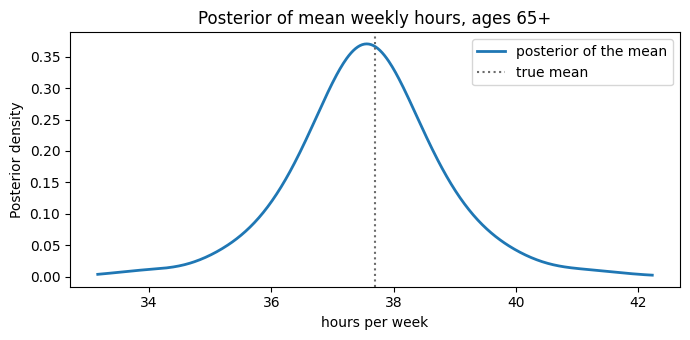

In [5]:
true_mean = people.loc[people["age"] >= 65, "hours"].clip(0, 80).mean()
lo, hi = sample_noisy_values(mean, n=20000, rng=np.random.default_rng(0))[0].credible_interval(0.95)
print(f"95% credible interval for the mean: [{lo:.2f}, {hi:.2f}]")
print(f"true mean (not normally available): {true_mean:.2f}")

fig, ax = plt.subplots(figsize=(7, 3.5))
plot_posterior(mean, ax=ax)
ax.get_lines()[-1].set_label("posterior of the mean")
ax.axvline(true_mean, color="#6b6b6b", linestyle=":", label="true mean")
ax.set_title("Posterior of mean weekly hours, ages 65+")
ax.set_xlabel("hours per week")
ax.legend()
plt.tight_layout()

## Bounds shape the posterior

DDuo's public bounds become prior knowledge. A count is never negative, so a
small count released with a lot of noise gets a posterior truncated at zero,
with no `low=0` needed. Here are the respondents aged 93 or over, released
with ε = 0.1 (Laplace scale 10). The noise happens to push the released
number below zero, but the posterior stays non-negative:

released: -4.8   smallest posterior draw: 0.00


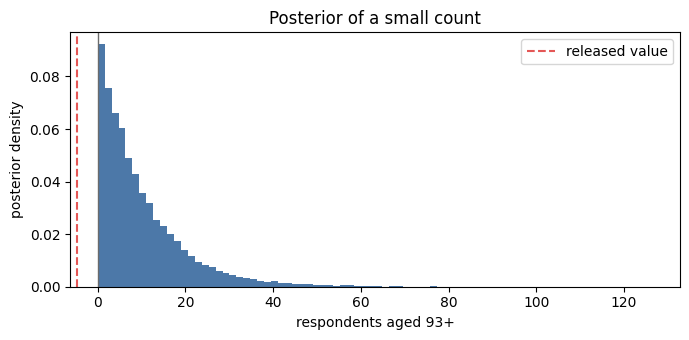

In [6]:
np.random.seed(7)
oldest = dduo.laplace((df["age"] >= 93).sum(), epsilon=0.1)

draws = sample_noisy_values(oldest, n=20000, rng=np.random.default_rng(0))[0].draws
print(f"released: {float(oldest):.1f}   smallest posterior draw: {draws.min():.2f}")

# a histogram of posterior draws: a smoothed density would blur the edge at zero
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(draws, bins=80, density=True, color="#4c78a8")
ax.axvline(float(oldest), color="#e45756", linestyle="--", label="released value")
ax.axvline(0, color="#6b6b6b", linewidth=1)
ax.set_title("Posterior of a small count")
ax.set_xlabel("respondents aged 93+")
ax.set_ylabel("posterior density")
ax.legend()
plt.tight_layout()

`low=` and `high=` add knowledge of your own. They can only narrow DDuo's
bounds, never widen them. For example, if the survey design guarantees at most
40 respondents in that age group:

In [7]:
np.random.seed(7)
capped = dduo.laplace((df["age"] >= 93).sum(), epsilon=0.1, high=40)
draws = sample_noisy_values(capped, n=20000, rng=np.random.default_rng(0))[0].draws
print(f"posterior draws lie in [{draws.min():.2f}, {draws.max():.2f}]")

posterior draws lie in [0.00, 40.00]


## Repeated releases of one statistic

DDuo tracks sensitivity, not *which* statistic a value is, so two releases of
the same count come back as two unrelated numbers. Give them a shared `key`
in a `SharedLatentRegistry` and they are combined in closed form, which works
for the Gaussian mechanism. Every value already issued under that key,
including `first`, tightens in place.

In [8]:
np.random.seed(2)
registry = SharedLatentRegistry()
n65 = (df["age"] >= 65).sum()

first = dduo.gauss(n65, epsilon=0.5, delta=1e-6, key="aged 65+", registry=registry)
sd_before = sample_noisy_values(first, n=20000, rng=np.random.default_rng(0))[0].draws.std()

second = dduo.gauss(n65, epsilon=0.5, delta=1e-6, key="aged 65+", registry=registry)
sd_after = sample_noisy_values(first, n=20000, rng=np.random.default_rng(0))[0].draws.std()

print(f"releases: {float(first):.1f}, {float(second):.1f}")
print(f"posterior sd of `first`: {sd_before:.2f} -> {sd_after:.2f}  (ratio {sd_before / sd_after:.3f}, about sqrt 2)")

releases: 199.6, 203.4
posterior sd of `first`: 10.56 -> 7.46  (ratio 1.414, about sqrt 2)


## Refusals cost nothing

A value DDuo cannot bound is refused *before* DDuo's mechanism runs, so no
privacy budget is charged for it. The same happens for values that are not
tracked at all (they might be private data that was never wrapped) and for
values that do not depend on the data.

In [9]:
with duet.EDOdometer() as odo:
    try:
        dduo.laplace(df["hours"].sum(), epsilon=1.0)
    except ValueError as e:
        print("refused:", e)
    try:
        dduo.laplace(people["hours"].sum(), epsilon=1.0)   # plain pandas: untracked
    except TypeError as e:
        print("refused:", e)
print(f"privacy spent: {odo.privacy_env}")

refused: Sensitivity is unbounded -- DDuo cannot bound how far one change to the data moves this value; clip it (or the data it is computed from) before releasing
refused: Expected a DuetWrapper (a value whose sensitivity DDuo tracks), got float64
privacy spent: []


## What is not wrapped

`duet.report_noisy_max` and `duet.above_threshold` release a *choice* (an
element or an index), not a noisy number, so there is no additive-noise
posterior to attach. Also note that a value released *because* a noisy test
picked it has a different posterior from the one built here (the winner's
curse).

Released values are public, but they are `NoisyFloat`s rather than numbers.
Convert them with `float(value)` before feeding them back into a DDuo
computation, for example a noisy gradient step.